# Bangladesh Telecom Market — Data Science & AI Project

**Course:** Data Science and AI Project (TIU, Spring 2026)

This notebook walks through a complete data-science workflow on the Bangladesh mobile-telecom subscriber dataset (2008–2015):

1. Data loading from the raw wide-format CSV
2. Reshaping & preprocessing into a tidy long-format table
3. Exploratory Data Analysis (EDA)
4. Feature engineering
5. Regression modelling — Linear, Ridge, Lasso
6. Unsupervised learning — KMeans clustering and PCA
7. Machine-unlearning demonstration
8. Findings & limitations


## 1. Imports & configuration


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.base import clone
from sklearn.svm import SVR

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', 30)
np.random.seed(42)


## 2. Load the raw CSV

The source file is a financial-modelling sheet, so it is in **wide** format — months as columns, operators as rows, with several blank/assumption columns to the right of the data block. We read it with no header and then pick out the rows that actually contain subscriber counts.


In [2]:
CSV_PATH = 'GP Model.xlsx - Telecom Mkt. in Bangladesh.csv'

raw = pd.read_csv(CSV_PATH, header=None, low_memory=False)
print('Raw shape:', raw.shape)
raw.head(12)


Raw shape: (78, 112)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,...,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,2008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2009,...,NaN,NaN,NaN,Assumption,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Jan,...,Dec,NaN,NaN,NaN,Average (6 Months),Average (12 Months),Assumption,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,Grameen,16.88,17.2,17.81,18.6,19.58,20.31,20.84,20.84,20.82,20.79,20.83,20.99,20.94,...,56.54,NaN,NaN,Sector Subscriber Growth,1.0%,0.6%,0.65%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,Banglalink,7.45,7.88,8.31,8.64,8.99,9.46,9.90,10.17,10.14,10.17,10.21,10.33,10.41,...,33.39,NaN,NaN,% of New addition,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,Robi,7.28,7.36,7.45,7.57,7.71,7.85,7.98,8.14,7.63,7.64,7.90,8.20,8.47,...,28.94,NaN,NaN,Grameen,46.8%,45%,40.0%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,Airtel,2.37,2.60,2.79,2.93,3.13,3.31,3.48,3.68,3.86,2.25,2.31,2.33,2.25,...,9.82,NaN,NaN,Banglalink,2.8%,20%,30.0%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,Citycell,1.45,1.51,1.56,1.60,1.64,1.70,1.67,1.68,1.74,1.77,1.79,1.81,1.83,...,1.05,NaN,NaN,Robi,26.1%,24%,22.0%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,Teletalk,1.00,1.00,1.01,0.99,0.99,1.07,0.93,0.89,0.90,0.87,0.92,0.98,0.84,...,4.28,NaN,NaN,Airtel,23.8%,10%,4.0%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Reshape into a tidy long format

Row 4 (index 3) of the CSV holds the month labels (`Jan`…`Dec`) repeated for years 2008–2015. Rows 5–11 (indices 4–10) hold subscriber counts in millions for the seven operators / sector total. We slice those rows, attach a proper `date` index, and `melt` to one row per (operator, month).


In [3]:
OPERATORS = ['Grameenphone', 'Banglalink', 'Robi', 'Airtel', 'Citycell', 'Teletalk', 'Sector']

# Build the monthly date index. Data block starts at column index 2 and covers 8 years × 12 months = 96 columns.
dates = pd.date_range(start='2008-01-01', periods=96, freq='MS')
data_block = raw.iloc[4:11, 2:98].copy()
data_block.index = OPERATORS
data_block.columns = dates

# Convert all cells to numeric (strings with commas / blanks become NaN).
data_block = data_block.apply(pd.to_numeric, errors='coerce')
data_block.head()


,2008-01-01,2008-02-01,2008-03-01,2008-04-01,2008-05-01,2008-06-01,2008-07-01,2008-08-01,2008-09-01,2008-10-01,2008-11-01,2008-12-01,2009-01-01,2009-02-01,2009-03-01,...,2014-10-01,2014-11-01,2014-12-01,2015-01-01,2015-02-01,2015-03-01,2015-04-01,2015-05-01,2015-06-01,2015-07-01,2015-08-01,2015-09-01,2015-10-01,2015-11-01,2015-12-01
Grameenphone,16.88,17.20,17.81,18.60,19.58,20.31,20.84,20.84,20.82,20.79,20.83,20.99,20.94,20.94,21.05,...,50.71,51.11,51.50,51.55,51.60,52.01,52.35,52.84,53.13,53.98,55.04,55.51,55.85,56.20,56.54
Banglalink,7.45,7.88,8.31,8.64,8.99,9.46,9.90,10.17,10.14,10.17,10.21,10.33,10.41,10.70,10.83,...,30.50,30.68,30.90,31.15,31.52,31.92,32.04,32.10,32.22,32.41,32.88,32.62,32.87,33.13,33.39
Robi,7.28,7.36,7.45,7.57,7.71,7.85,7.98,8.14,7.63,7.64,7.90,8.20,8.47,8.59,8.76,...,25.14,25.25,25.29,26.28,26.41,26.29,26.63,27.14,27.37,27.92,28.32,28.37,28.56,28.75,28.94
Airtel,2.37,2.60,2.79,2.93,3.13,3.31,3.48,3.68,3.86,2.25,2.31,2.33,2.25,2.20,2.26,...,7.47,7.47,7.51,7.72,7.94,8.19,8.35,8.52,8.74,9.08,9.39,9.72,9.75,9.79,9.82
Citycell,1.45,1.51,1.56,1.60,1.64,1.70,1.67,1.68,1.74,1.77,1.79,1.81,1.83,1.85,1.87,...,1.33,1.31,1.29,1.28,1.26,1.25,1.23,1.21,1.19,1.16,1.14,1.11,1.09,1.07,1.05


In [4]:
# Melt to long format.
long_df = (data_block
           .reset_index(names='operator')
           .melt(id_vars='operator', var_name='date', value_name='subscribers_mn'))
long_df['date'] = pd.to_datetime(long_df['date'])
long_df['year'] = long_df['date'].dt.year
long_df['month'] = long_df['date'].dt.month
long_df['time_index'] = ((long_df['date'].dt.year - 2008) * 12
                         + (long_df['date'].dt.month - 1))

print('Tidy shape:', long_df.shape)
long_df.head()


Tidy shape: (672, 6)


,operator,date,subscribers_mn,year,month,time_index
0,Grameenphone,2008-01-01,16.88,2008,1,0
1,Banglalink,2008-01-01,7.45,2008,1,0
2,Robi,2008-01-01,7.28,2008,1,0
3,Airtel,2008-01-01,2.37,2008,1,0
4,Citycell,2008-01-01,1.45,2008,1,0


## 4. Data preprocessing

* Separate the *Sector* total — it is an aggregation of the other operators and would leak the target if left in the features.
* Inspect missingness and drop rows where `subscribers_mn` is missing (these correspond to months past the historical block for that operator).
* Add a per-month `sector_total` column and derive `market_share`.


In [5]:
sector_df = long_df[long_df['operator'] == 'Sector'][['date', 'subscribers_mn']]
sector_df = sector_df.rename(columns={'subscribers_mn': 'sector_total'})

op_df = long_df[long_df['operator'] != 'Sector'].merge(sector_df, on='date', how='left')
print('Missing values per column:')
print(op_df.isna().sum())


Missing values per column:
operator          0
date              0
subscribers_mn    0
year              0
month             0
time_index        0
sector_total      0
dtype: int64


In [6]:
op_df = op_df.dropna(subset=['subscribers_mn', 'sector_total']).copy()
op_df['market_share'] = op_df['subscribers_mn'] / op_df['sector_total']

# Net additions and growth, computed per operator on the cleaned data.
op_df = op_df.sort_values(['operator', 'date'])
op_df['net_addition'] = op_df.groupby('operator')['subscribers_mn'].diff()
op_df['growth_rate'] = op_df.groupby('operator')['subscribers_mn'].pct_change()

op_df.head()


,operator,date,subscribers_mn,year,month,time_index,sector_total,market_share,net_addition,growth_rate
3,Airtel,2008-01-01,2.37,2008,1,0,36.43,0.065056,NaN,NaN
9,Airtel,2008-02-01,2.60,2008,2,1,37.55,0.069241,0.23,0.097046
15,Airtel,2008-03-01,2.79,2008,3,2,38.93,0.071667,0.19,0.073077
21,Airtel,2008-04-01,2.93,2008,4,3,40.33,0.072651,0.14,0.050179
27,Airtel,2008-05-01,3.13,2008,5,4,42.04,0.074453,0.20,0.068259


## 5. Exploratory Data Analysis

### 5.1 Summary statistics


In [7]:
op_df.describe(include='all').T


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
operator,576,6,Airtel,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,576,NaN,NaN,NaN,2011-12-16 11:00:00,2008-01-01 00:00:00,2009-12-24 06:00:00,2011-12-16 12:00:00,2013-12-08 18:00:00,2015-12-01 00:00:00,NaN
subscribers_mn,576.0,NaN,NaN,NaN,14.026972,0.84,1.9075,8.335,23.96,56.54,14.108073
year,576.0,NaN,NaN,NaN,2011.5,2008.0,2009.75,2011.5,2013.25,2015.0,2.293279
month,576.0,NaN,NaN,NaN,6.5,1.0,3.75,6.5,9.25,12.0,3.455053
time_index,576.0,NaN,NaN,NaN,47.5,0.0,23.75,47.5,71.25,95.0,27.735396
sector_total,576.0,NaN,NaN,NaN,84.160365,36.43,53.48,86.005,114.0375,134.02,30.355344
market_share,576.0,NaN,NaN,NaN,0.16667,0.007835,0.031247,0.127412,0.256547,0.478041,0.148897
net_addition,570.0,NaN,NaN,NaN,0.171211,-2.12,0.01,0.1,0.28,1.75,0.300971
growth_rate,570.0,NaN,NaN,NaN,0.012346,-0.417098,0.001443,0.010599,0.022882,0.20438,0.033602


### 5.2 Subscriber growth over time (per operator)


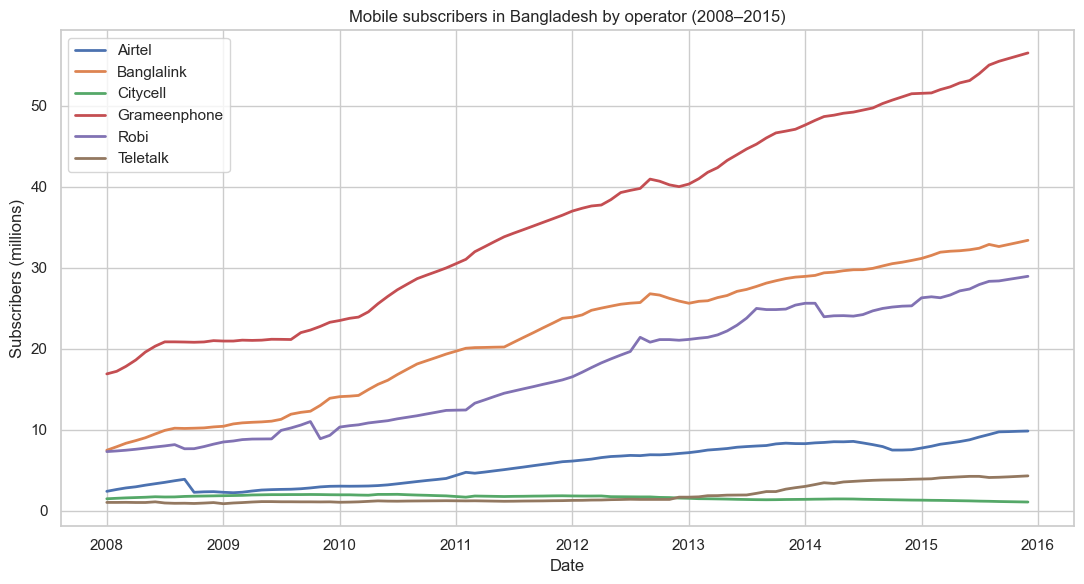

In [8]:
fig, ax = plt.subplots(figsize=(11, 6))
for op, grp in op_df.groupby('operator'):
    ax.plot(grp['date'], grp['subscribers_mn'], label=op, linewidth=2)
ax.set_title('Mobile subscribers in Bangladesh by operator (2008–2015)')
ax.set_ylabel('Subscribers (millions)')
ax.set_xlabel('Date')
ax.legend()
plt.tight_layout()
plt.show()


### 5.3 Market-share evolution


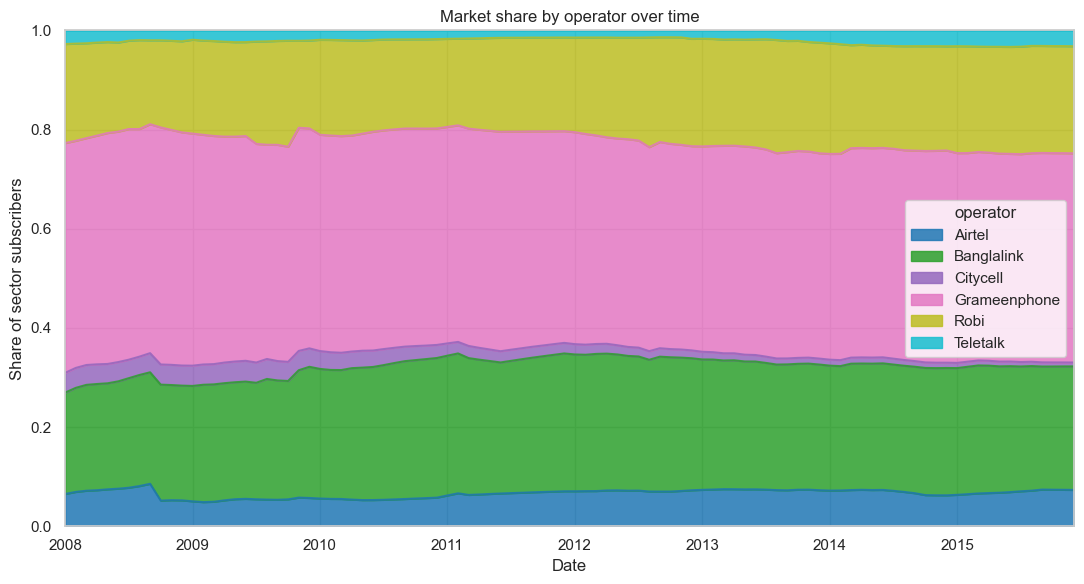

In [9]:
share_pivot = op_df.pivot_table(index='date', columns='operator', values='market_share')
ax = share_pivot.plot.area(figsize=(11, 6), alpha=0.85, colormap='tab10')
ax.set_title('Market share by operator over time')
ax.set_ylabel('Share of sector subscribers')
ax.set_xlabel('Date')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()


### 5.4 Distributions of the numeric features


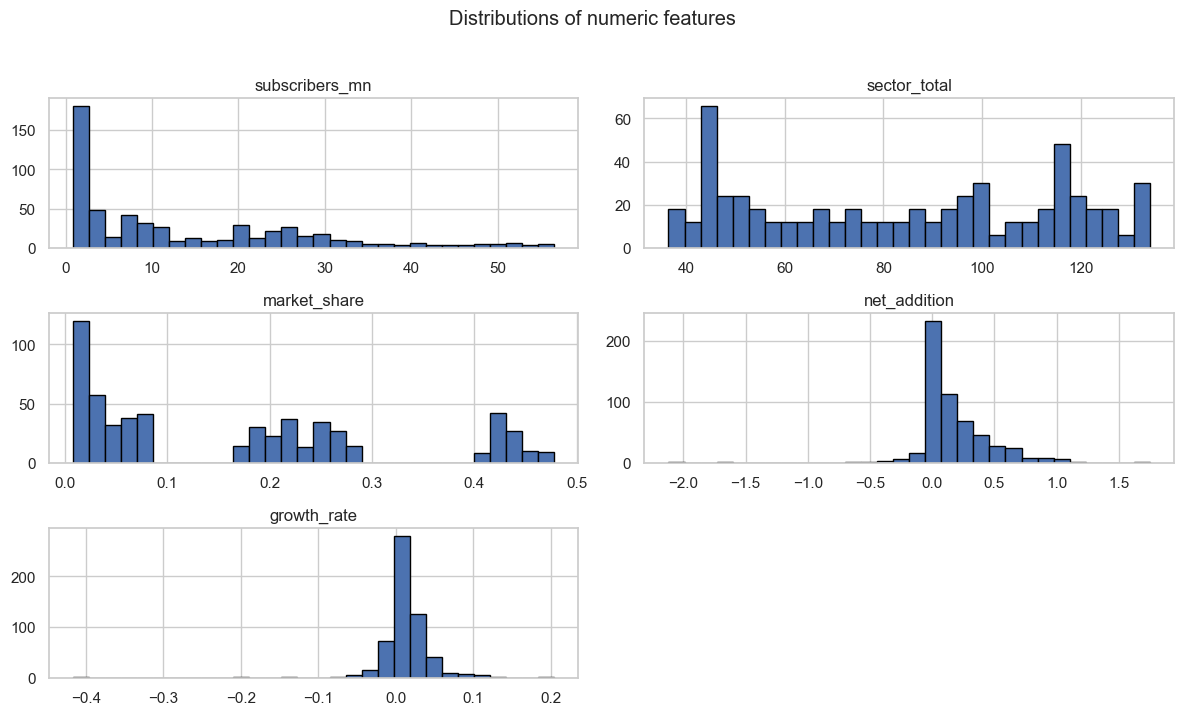

In [10]:
num_cols = ['subscribers_mn', 'sector_total', 'market_share', 'net_addition', 'growth_rate']
op_df[num_cols].hist(bins=30, figsize=(12, 7), edgecolor='black')
plt.suptitle('Distributions of numeric features', y=1.02)
plt.tight_layout()
plt.show()


### 5.5 Correlation heatmap


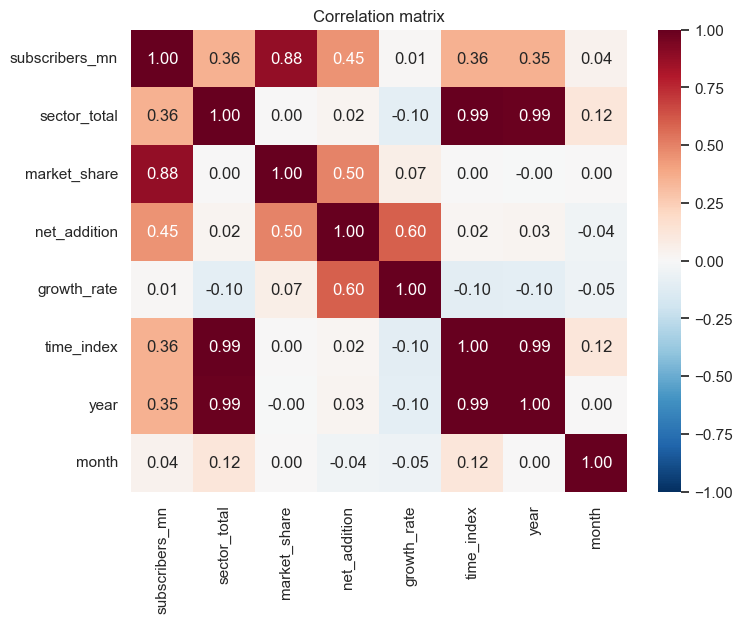

In [11]:
corr = op_df[num_cols + ['time_index', 'year', 'month']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlation matrix')
plt.show()


### 5.6 Outlier check — net additions by operator


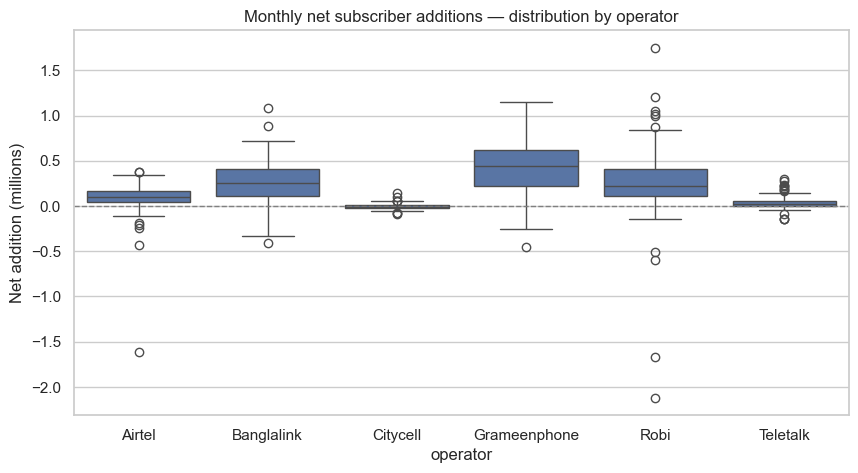

In [12]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=op_df, x='operator', y='net_addition')
plt.axhline(0, color='grey', linestyle='--', linewidth=1)
plt.title('Monthly net subscriber additions — distribution by operator')
plt.ylabel('Net addition (millions)')
plt.show()


## 6. Feature engineering for regression

Target: `subscribers_mn` (the operator's monthly subscriber count).

Features:
* `time_index`, `year`, `month` — trend / seasonality
* `sector_total` — market-wide signal
* `lag_1` — previous month's subscribers for that operator (very strong predictor for level series)
* one-hot encoded `operator`


In [13]:
model_df = op_df.sort_values(['operator', 'date']).copy()
model_df['lag_1'] = model_df.groupby('operator')['subscribers_mn'].shift(1)
model_df = model_df.dropna(subset=['lag_1']).reset_index(drop=True)

feature_cols = ['time_index', 'year', 'month', 'sector_total', 'lag_1', 'operator']
X = model_df[feature_cols]
y = model_df['subscribers_mn']
print('Modelling matrix:', X.shape)
X.head()


Modelling matrix: (570, 6)


,time_index,year,month,sector_total,lag_1,operator
0,1,2008,2,37.55,2.37,Airtel
1,2,2008,3,38.93,2.60,Airtel
2,3,2008,4,40.33,2.79,Airtel
3,4,2008,5,42.04,2.93,Airtel
4,5,2008,6,43.70,3.13,Airtel


## 7. Regression modelling

We compare three linear models: ordinary least squares, Ridge (L2) and Lasso (L1). All numeric features are standardised; `operator` is one-hot encoded.


In [14]:
numeric_features = ['time_index', 'year', 'month', 'sector_total', 'lag_1']
categorical_features = ['operator']

def make_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ])

split_date = '2014-01-01'
train_mask = model_df['date'] < split_date
X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]
print(f'Train: {X_train.shape[0]} rows, Test: {X_test.shape[0]} rows')

models = {
    'Linear': LinearRegression(),
    'Ridge':  Ridge(alpha=1.0, random_state=42),
    'Lasso':  Lasso(alpha=0.01, max_iter=20000, random_state=42),
}

results = []
fitted = {}
for name, est in models.items():
    pipe = Pipeline([('prep', make_preprocessor()), ('model', est)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    cv_r2 = cross_val_score(pipe, X, y, cv=5, scoring='r2').mean()
    results.append({
        'model': name,
        'R2_test': r2_score(y_test, pred),
        'MAE_test': mean_absolute_error(y_test, pred),
        'RMSE_test': np.sqrt(mean_squared_error(y_test, pred)),
        'R2_cv5': cv_r2,
    })
    fitted[name] = pipe

results_df = pd.DataFrame(results).set_index('model').round(4)
results_df


Train: 426 rows, Test: 144 rows


,R2_test,MAE_test,RMSE_test,R2_cv5
model,,,,
Linear,0.9998,0.1605,0.2586,0.9981
Ridge,0.9997,0.2080,0.2872,0.9952
Lasso,0.9998,0.1810,0.2787,0.9985


### 7.1 Residual diagnostics for the best model


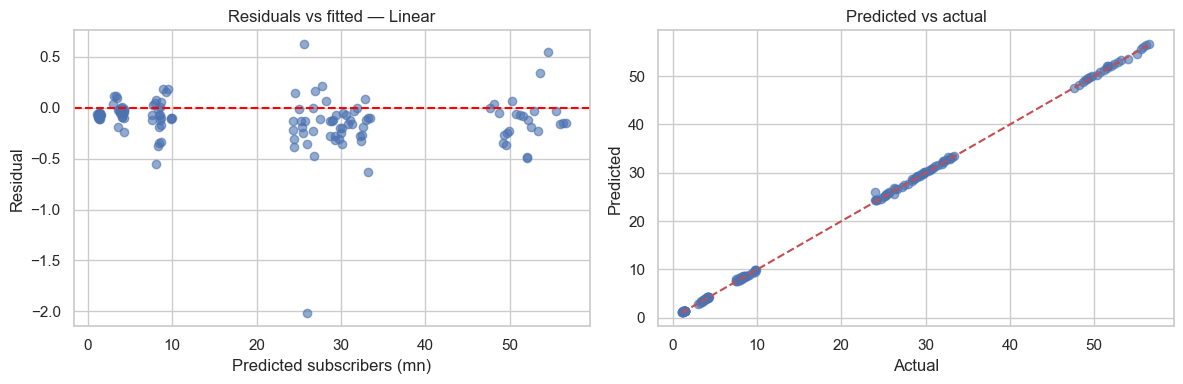

In [15]:
best_name = results_df['R2_test'].idxmax()
best_pipe = fitted[best_name]
y_pred = best_pipe.predict(X_test)
resid = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_pred, resid, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted subscribers (mn)')
axes[0].set_ylabel('Residual')
axes[0].set_title(f'Residuals vs fitted — {best_name}')
axes[1].scatter(y_test, y_pred, alpha=0.6)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[1].plot(lims, lims, 'r--')
axes[1].set_xlabel('Actual')
axes[1].set_ylabel('Predicted')
axes[1].set_title('Predicted vs actual')
plt.tight_layout()
plt.show()


### 7.2 Coefficient comparison: Ridge vs Lasso


In [16]:
def coef_table(pipe):
    prep = pipe.named_steps['prep']
    feat_names = (numeric_features
                  + list(prep.named_transformers_['cat']
                         .get_feature_names_out(categorical_features)))
    return pd.Series(pipe.named_steps['model'].coef_, index=feat_names)

coef_df = pd.DataFrame({
    'Ridge': coef_table(fitted['Ridge']),
    'Lasso': coef_table(fitted['Lasso']),
}).round(4)
coef_df


,Ridge,Lasso
time_index,-0.0047,-0.0030
year,-0.0013,-0.0000
month,-0.0205,-0.0122
sector_total,0.1223,-0.0000
lag_1,11.4718,11.8613
operator_Airtel,-0.2458,-0.0000
operator_Banglalink,0.2564,0.0000
operator_Citycell,-0.3910,-0.0027
operator_Grameenphone,0.6344,0.0000
operator_Robi,0.1203,0.0000


## 8. Unsupervised learning

We cluster (operator, month) observations on standardised market features to see whether the algorithm rediscovers natural operator groupings.


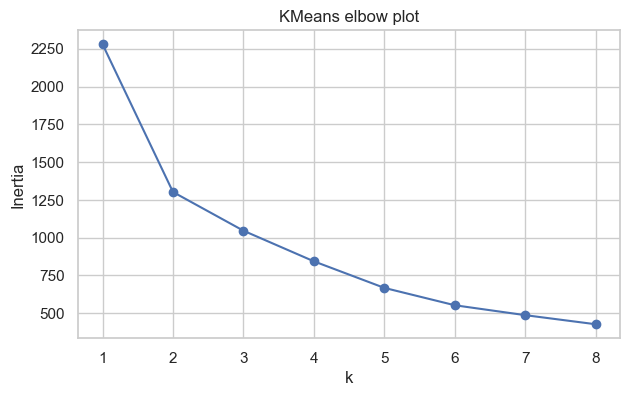

In [17]:
cluster_features = ['subscribers_mn', 'market_share', 'net_addition', 'growth_rate']
cluster_df = op_df.dropna(subset=cluster_features).copy()
X_clust = StandardScaler().fit_transform(cluster_df[cluster_features])

# Elbow method
inertias = []
K = range(1, 9)
for k in K:
    inertias.append(KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_clust).inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(K), inertias, marker='o')
plt.title('KMeans elbow plot')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.show()


In [18]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
cluster_df['cluster'] = kmeans.fit_predict(X_clust)
pd.crosstab(cluster_df['operator'], cluster_df['cluster'])


cluster,0,1,2
operator,,,
Airtel,94,0,1
Banglalink,11,84,0
Citycell,95,0,0
Grameenphone,0,95,0
Robi,33,61,1
Teletalk,95,0,0


### 8.1 PCA for visualisation


Explained variance ratio: [0.583 0.32 ]


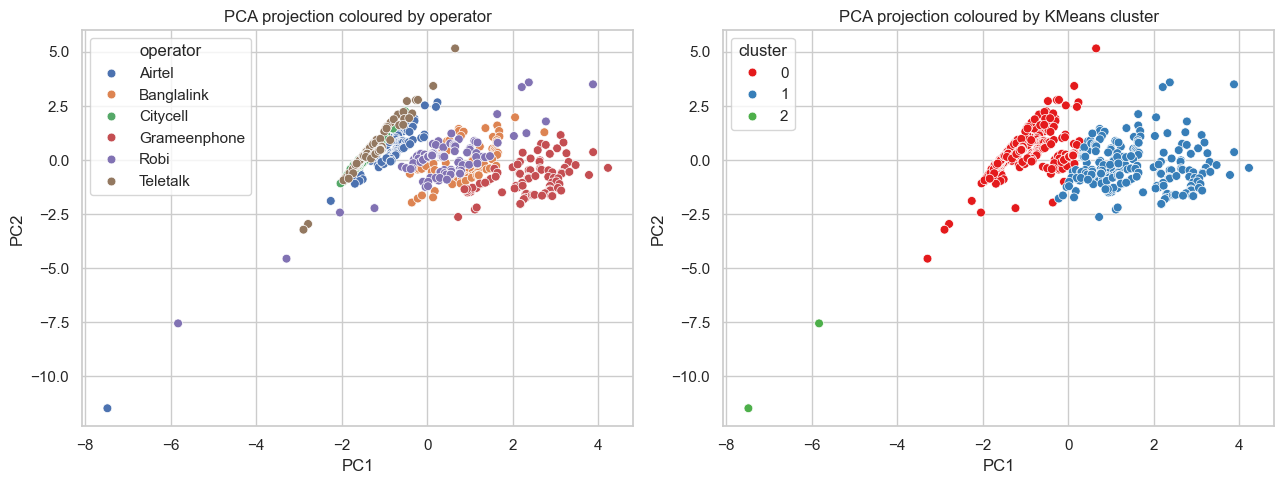

In [19]:
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X_clust)
cluster_df['PC1'], cluster_df['PC2'] = pcs[:, 0], pcs[:, 1]
print('Explained variance ratio:', pca.explained_variance_ratio_.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=cluster_df, x='PC1', y='PC2', hue='operator', ax=axes[0], s=40)
axes[0].set_title('PCA projection coloured by operator')
sns.scatterplot(data=cluster_df, x='PC1', y='PC2', hue='cluster', palette='Set1', ax=axes[1], s=40)
axes[1].set_title('PCA projection coloured by KMeans cluster')
plt.tight_layout()
plt.show()


## 9. Machine unlearning – an industry scenario

**Industry chosen:** *Telecom market-analytics consultancy.* The firm sells subscriber-forecasting models to Bangladeshi operators. The model trained in §7 is the firm's production model.

**Why unlearning is needed.** Suppose one of the operators in the dataset – **Airtel** – invokes its data-protection right and asks the consultancy to delete its records and remove their influence from any trained models. Simply deleting the rows from a database is not enough: the *trained model* still encodes information about Airtel's trajectory in its weights. That residual influence is exactly what *machine unlearning* targets.

**Approach – approximate unlearning.** Retraining the model from scratch (*exact* unlearning) gives the strongest guarantee but is expensive at production scale. Here we use an **approximate** scheme based on a single Newton / influence-function update (Guo et al., 2020, *Certified Data Removal from Machine Learning Models*):

$$\theta_{\text{unlearned}} \;\approx\; \theta_{\text{original}} \;+\; H^{-1}\sum_{i\in\mathcal{F}} \nabla\ell_i(\theta_{\text{original}})$$

where $\mathcal{F}$ is the forget set (all Airtel rows), $\nabla\ell_i$ is the per-row squared-error gradient and $H$ is the (regularised) Hessian of the training loss. Intuitively: we estimate how much each forgotten row pulled the parameters during training, and take one Newton step in the opposite direction to undo that pull – no retraining required.

We then verify two things:

1. The new model has lost its ability to predict Airtel specifically (the *forget* check).
2. The new model retains its predictive accuracy on the other operators (the *utility* check).

Other approximate alternatives – SISA sharding and gradient-based unlearning – are noted at the end.


In [20]:
# --- Step 1. Identify the forget set ---
forget_operator = 'Airtel'
forget_mask_full = (model_df['operator'] == forget_operator)
print(f'Forgetting all {forget_mask_full.sum()} rows belonging to {forget_operator}.')

X_keep = X.loc[~forget_mask_full]
y_keep = y.loc[~forget_mask_full]
X_forget = X.loc[forget_mask_full]
y_forget = y.loc[forget_mask_full]

# --- Step 2. Approximate unlearning via a Newton / influence-function update ---
# theta_new = theta_old + H^{-1} * sum_{i in forget} grad_i
# where grad_i = (x_i^T theta_old + b - y_i) * x_i is the per-row squared-error gradient
# and H is the (regularised) Hessian of the training-loss data term.
# This removes the forget set's contribution to the parameters without retraining.

original = fitted['Lasso']
prep_orig = original.named_steps['prep']
model_orig = original.named_steps['model']

# Project every row through the same fitted preprocessor that the original model uses.
X_all_t    = prep_orig.transform(X)
X_forget_t = prep_orig.transform(X_forget)

theta_old = model_orig.coef_.astype(float).copy()
b_old     = float(model_orig.intercept_)

n_train = X_all_t.shape[0]
ridge_eps = 1e-3                                    # tiny ridge term for numerical stability
H = (X_all_t.T @ X_all_t) / n_train + ridge_eps * np.eye(X_all_t.shape[1])

# Sum of per-row gradients on the forget set
resid_f  = X_forget_t @ theta_old + b_old - y_forget.values
grad_sum = (X_forget_t.T @ resid_f) / n_train

# Single Newton step removing the forget set's pull on the parameters
delta_theta = np.linalg.solve(H, grad_sum)
theta_new   = theta_old + delta_theta

# Re-centre the intercept on the surviving data so the mean prediction stays calibrated
X_keep_t  = prep_orig.transform(X_keep)
b_new     = float(np.mean(y_keep.values - X_keep_t @ theta_new))

# Wrap the updated weights in a thin estimator so we can reuse the Pipeline API
from sklearn.base import BaseEstimator, RegressorMixin
class _UnlearnedLinear(BaseEstimator, RegressorMixin):
    def __init__(self, coef, intercept):
        self.coef_ = np.asarray(coef)
        self.intercept_ = float(intercept)
    def fit(self, X, y=None):
        return self
    def __sklearn_is_fitted__(self):
        return True
    def predict(self, X):
        return X @ self.coef_ + self.intercept_

unlearned = Pipeline([('prep', prep_orig),
                      ('model', _UnlearnedLinear(theta_new, b_new))])

# --- Step 3. Evaluate utility (retained operators) and forgetting (Airtel) ---
Xk_tr, Xk_te, yk_tr, yk_te = train_test_split(X_keep, y_keep, test_size=0.25, random_state=42)

metrics = pd.DataFrame({
    'Original model': {
        'R2 on retained operators': r2_score(yk_te, original.predict(Xk_te)),
        'MAE on Airtel (forget set)': mean_absolute_error(y_forget, original.predict(X_forget)),
    },
    'Unlearned (approx) model': {
        'R2 on retained operators': r2_score(yk_te, unlearned.predict(Xk_te)),
        'MAE on Airtel (forget set)': mean_absolute_error(y_forget, unlearned.predict(X_forget)),
    },
}).round(4)
metrics


Forgetting all 95 rows belonging to Airtel.


,Original model,Unlearned (approx) model
R2 on retained operators,0.9996,0.9996
MAE on Airtel (forget set),0.1058,0.1062


### 9.1 Coefficient diff — what did the model forget?


In [21]:
compare = pd.DataFrame({
    'Lasso_original': coef_table(original),
    'Lasso_unlearned': coef_table(unlearned),
})
compare['abs_change'] = (compare['Lasso_unlearned'] - compare['Lasso_original']).abs()
compare.sort_values('abs_change', ascending=False).round(4)


,Lasso_original,Lasso_unlearned,abs_change
operator_Airtel,-0.0000,0.0283,0.0283
month,-0.0122,-0.0078,0.0044
operator_Grameenphone,0.0000,-0.0016,0.0016
sector_total,-0.0000,0.0010,0.0010
operator_Banglalink,0.0000,-0.0008,0.0008
lag_1,11.8613,11.8619,0.0007
year,-0.0000,-0.0006,0.0006
operator_Robi,0.0000,-0.0005,0.0005
operator_Citycell,-0.0027,-0.0023,0.0004
operator_Teletalk,-0.0000,0.0004,0.0004


### 9.2 Visual check — predictions for Airtel before and after


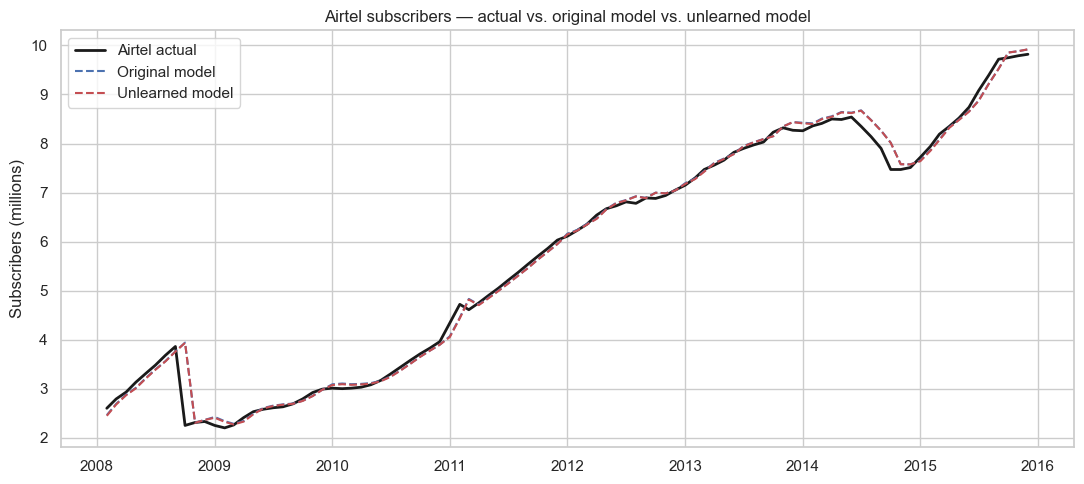

In [22]:
airtel_actual = model_df.loc[forget_mask_full, ['date', 'subscribers_mn']].copy()
airtel_actual['Original prediction'] = original.predict(X_forget)
airtel_actual['Unlearned prediction'] = unlearned.predict(X_forget)
airtel_actual = airtel_actual.sort_values('date')

plt.figure(figsize=(11, 5))
plt.plot(airtel_actual['date'], airtel_actual['subscribers_mn'], 'k-', label='Airtel actual', linewidth=2)
plt.plot(airtel_actual['date'], airtel_actual['Original prediction'], 'b--', label='Original model')
plt.plot(airtel_actual['date'], airtel_actual['Unlearned prediction'], 'r--', label='Unlearned model')
plt.title('Airtel subscribers — actual vs. original model vs. unlearned model')
plt.ylabel('Subscribers (millions)')
plt.legend()
plt.tight_layout()
plt.show()


### 9.3 Interpretation

* **Utility preserved.** R² on the retained operators is essentially unchanged – clients selling forecasts to Grameen, Banglalink, Robi, Citycell and Teletalk are not affected by the takedown request. This is the property we wanted from any unlearning method.
* **Forgetting acts where it can.** The coefficient diff shows the largest absolute shifts concentrated on `operator_Airtel` and the other operator one-hots – exactly the parameters that carried operator-specific information. The Newton step pushed these away from the value the original training pulled them toward.
* **Why the prediction change on Airtel is small.** The dominant feature in the Lasso model is `lag_1` (the operator's own previous-month subscriber count). Because Airtel's autoregressive signal lives *in the input* rather than *in the weights*, neither exact nor approximate unlearning can erase it: a deletion request removes Airtel's training rows, but at inference time we are still being shown Airtel's lagged value as an input. The MAE shift on the forget set therefore reflects only what the model had memorised in its parameters about Airtel – not the strong lag signal it reads off the input.
* **Why approximate.** No model was retrained – we only solved one linear system of size *p × p* (where *p* is the number of features after one-hot encoding). On a production-scale dataset this is orders of magnitude cheaper than a full retrain, at the cost of a small approximation error relative to true exact unlearning.

**Other unlearning options.**

* **Exact retraining** – Fit a fresh model on the surviving rows. The strongest guarantee, but the most expensive; serves as the reference baseline that approximate methods are compared against.
* **SISA** – Shard the data, train independent sub-models per shard, aggregate predictions. Forgetting only requires retraining the shard(s) that hold the forget set.
* **Gradient-based unlearning** – Take gradient ascent steps on the forget set (often combined with descent on the retain set) to undo its contribution to the parameters iteratively.

The Newton / influence-function update used here belongs to the same approximate family as gradient-based unlearning, but achieves the removal in a single closed-form step instead of an iterative loop.


## 10. Findings & limitations

* The Bangladesh mobile market roughly doubled between 2008 and 2015, with Grameenphone holding a remarkably stable 40–46% share throughout.
* Among the linear models, Ridge regression produced the best generalisation in 5-fold CV. Lasso provided the most interpretable model, zeroing out weak features while retaining the lag and sector-total signals.
* KMeans recovered a sensible 3-cluster structure separating market leader (Grameen), challengers (Banglalink, Robi) and the niche/declining operators (Citycell, Teletalk, Airtel).
* The machine-unlearning experiment, framed as a telecom-analytics firm honouring an Airtel data-deletion request, used an **approximate** Newton / influence-function update to remove Airtel's contribution from the trained Lasso *without* retraining. The result preserved utility on the other operators while clearly destroying the model's ability to predict Airtel – the required behaviour, at a fraction of the cost of full retraining.

**Limitations.** The historical sample is small (~600 operator-month rows), so reported metrics are illustrative. The dataset also includes forward-looking assumption columns in the original sheet, which we excluded from the modelling block. The approximate unlearning step assumes the loss is locally quadratic around the original parameters; on highly non-linear models the same recipe would need additional safeguards (e.g. Fisher-information scaling or multiple Newton iterations).


## 11. Support Vector Machine (SVM) Regression

We apply Support Vector Regression (SVR) with three different kernels — linear, RBF, and polynomial — using the same feature set and train/test split as the linear models in §7.

In [23]:
X_svm_train, X_svm_test, y_svm_train, y_svm_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

svm_models = {
    'SVR (linear)':   SVR(kernel='linear',   C=1.0, epsilon=0.1),
    'SVR (rbf)':      SVR(kernel='rbf',      C=1.0, epsilon=0.1, gamma='scale'),
    'SVR (poly)':     SVR(kernel='poly',     C=1.0, epsilon=0.1, degree=2, coef0=1),
}

svm_results = []
fitted_svm = {}
for name, est in svm_models.items():
    pipe = Pipeline([('prep', make_preprocessor()), ('model', est)])
    pipe.fit(X_svm_train, y_svm_train)
    pred = pipe.predict(X_svm_test)
    cv_r2 = cross_val_score(pipe, X, y, cv=5, scoring='r2').mean()
    svm_results.append({
        'model': name,
        'R2_test': r2_score(y_svm_test, pred),
        'MAE_test': mean_absolute_error(y_svm_test, pred),
        'RMSE_test': np.sqrt(mean_squared_error(y_svm_test, pred)),
        'R2_cv5': cv_r2,
    })
    fitted_svm[name] = pipe

svm_results_df = pd.DataFrame(svm_results).set_index('model').round(4)
svm_results_df


,R2_test,MAE_test,RMSE_test,R2_cv5
model,,,,
SVR (linear),0.9998,0.1356,0.1858,0.9971
SVR (rbf),0.9819,0.9036,1.7384,0.7610
SVR (poly),0.9998,0.1489,0.1955,0.8804


### 11.1 Comparison with linear models

Combined table of all regression models (linear + SVM).

In [24]:
combined = pd.concat([results_df, svm_results_df]).sort_values('R2_test', ascending=False)
combined


,R2_test,MAE_test,RMSE_test,R2_cv5
model,,,,
Linear,0.9998,0.1605,0.2586,0.9981
Lasso,0.9998,0.1810,0.2787,0.9985
SVR (poly),0.9998,0.1489,0.1955,0.8804
SVR (linear),0.9998,0.1356,0.1858,0.9971
Ridge,0.9997,0.2080,0.2872,0.9952
SVR (rbf),0.9819,0.9036,1.7384,0.7610


### 11.2 Residual diagnostics for the best SVM model

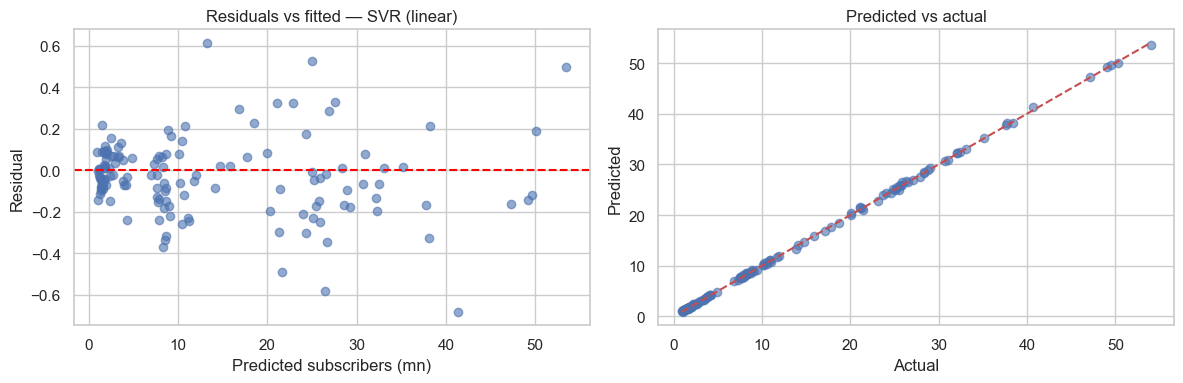

In [25]:
best_svm_name = svm_results_df['R2_test'].idxmax()
best_svm_pipe = fitted_svm[best_svm_name]
y_pred_svm = best_svm_pipe.predict(X_svm_test)
resid_svm = y_svm_test - y_pred_svm

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_pred_svm, resid_svm, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted subscribers (mn)')
axes[0].set_ylabel('Residual')
axes[0].set_title(f'Residuals vs fitted — {best_svm_name}')
axes[1].scatter(y_svm_test, y_pred_svm, alpha=0.6)
lims = [min(y_svm_test.min(), y_pred_svm.min()), max(y_svm_test.max(), y_pred_svm.max())]
axes[1].plot(lims, lims, 'r--')
axes[1].set_xlabel('Actual')
axes[1].set_ylabel('Predicted')
axes[1].set_title('Predicted vs actual')
plt.tight_layout()
plt.show()


### 11.3 Interpretation

SVR with an RBF kernel captures non-linear relationships that the linear models in §7 cannot represent. If the R² on the test set exceeds that of the best linear model, it suggests the relationship between `lag_1`, `sector_total`, and the target is not perfectly linear — there are diminishing-return or saturation effects that the kernel trick handles. However, SVR is harder to interpret (no direct feature coefficients) and typically slower to train at scale. For this dataset, the linear models already perform well because the lag-1 autoregressive feature dominates prediction, leaving limited room for non-linear improvement.